In [2]:
# importing libraries for deep learning using sklearn neural network
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)
from imblearn.combine import SMOTETomek
import joblib
import warnings
warnings.filterwarnings('ignore')

print('All libraries imported successfully!')

All libraries imported successfully!


In [3]:
# loading same stroke dataset
df = pd.read_csv(r'C:\Users\Ar\Desktop\multi-model-strok-prediction\data\stroke-dataset.csv')

# fix missing bmi
df['bmi'] = df['bmi'].fillna(df['bmi'].median())

# drop id
df = df.drop(['id'], axis=1)

# encode categorical columns
df_encoded = pd.get_dummies(df, columns=['gender', 'ever_married', 'work_type',
                                          'Residence_type', 'smoking_status'],
                             drop_first=True)

X = df_encoded.drop('stroke', axis=1)
y = df_encoded['stroke']

print('Data loaded and preprocessed!')
print('X shape:', X.shape)

Data loaded and preprocessed!
X shape: (5110, 16)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

smote_tomek = SMOTETomek(random_state=42)
X_train_resampled, y_train_resampled = smote_tomek.fit_resample(X_train_scaled, y_train)

print('Before SMOTETomek:', dict(zip(*np.unique(y_train, return_counts=True))))
print('After SMOTETomek:', dict(zip(*np.unique(y_train_resampled, return_counts=True))))

  File "c:\Users\Ar\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 268, in _count_physical_cores
    cpu_count_physical = sum(map(int, cpu_info))
                         ^^^^^^^^^^^^^^^^^^^^^^^


Before SMOTETomek: {0: 3889, 1: 199}
After SMOTETomek: {0: 3858, 1: 3858}


In [5]:
# MLP = Multi Layer Perceptron = Neural Network
# hidden_layer_sizes = (64, 32, 16) means 3 hidden layers
# same architecture as PyTorch/TensorFlow version
model_dl = MLPClassifier(
    hidden_layer_sizes=(64, 32, 16),
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    max_iter=100,
    batch_size=32,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.2,
    verbose=True
)

print('Training Neural Network...')
model_dl.fit(X_train_resampled, y_train_resampled)
print('Training complete!')

Training Neural Network...
Iteration 1, loss = 0.49261677
Validation score: 0.824482
Iteration 2, loss = 0.38331220
Validation score: 0.824482
Iteration 3, loss = 0.35348023
Validation score: 0.841321
Iteration 4, loss = 0.32750495
Validation score: 0.856218
Iteration 5, loss = 0.30569433
Validation score: 0.865933
Iteration 6, loss = 0.28500646
Validation score: 0.882772
Iteration 7, loss = 0.26219379
Validation score: 0.883420
Iteration 8, loss = 0.24837841
Validation score: 0.895078
Iteration 9, loss = 0.22936138
Validation score: 0.893782
Iteration 10, loss = 0.21826852
Validation score: 0.908031
Iteration 11, loss = 0.20153924
Validation score: 0.901554
Iteration 12, loss = 0.19166999
Validation score: 0.901554
Iteration 13, loss = 0.18241473
Validation score: 0.920337
Iteration 14, loss = 0.17455542
Validation score: 0.922280
Iteration 15, loss = 0.16898830
Validation score: 0.919689
Iteration 16, loss = 0.15575899
Validation score: 0.927461
Iteration 17, loss = 0.14924967
Valida

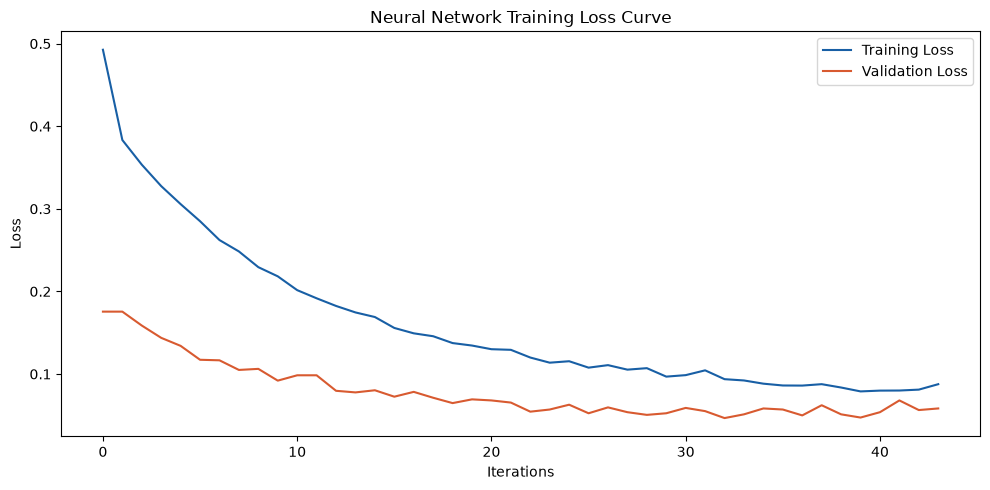

In [6]:
# plotting training loss curve
plt.figure(figsize=(10, 5))
plt.plot(model_dl.loss_curve_, color='#185FA5', label='Training Loss')
if model_dl.validation_scores_ is not None:
    plt.plot([1 - s for s in model_dl.validation_scores_],
             color='#D85A30', label='Validation Loss')
plt.title('Neural Network Training Loss Curve')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
# predictions
y_pred_dl = model_dl.predict(X_test_scaled)
y_pred_proba_dl = model_dl.predict_proba(X_test_scaled)[:, 1]

print('Neural Network (MLP) Results:')
print('Accuracy: ', round(accuracy_score(y_test, y_pred_dl) * 100, 2), '%')
print('Precision:', round(precision_score(y_test, y_pred_dl) * 100, 2), '%')
print('Recall:   ', round(recall_score(y_test, y_pred_dl) * 100, 2), '%')
print('F1 Score: ', round(f1_score(y_test, y_pred_dl) * 100, 2), '%')
print('AUC:      ', round(roc_auc_score(y_test, y_pred_proba_dl), 3))

Neural Network (MLP) Results:
Accuracy:  86.89 %
Precision: 12.5 %
Recall:    28.0 %
F1 Score:  17.28 %
AUC:       0.766


True Negative:  874
False Positive: 98
False Negative: 36
True Positive:  14


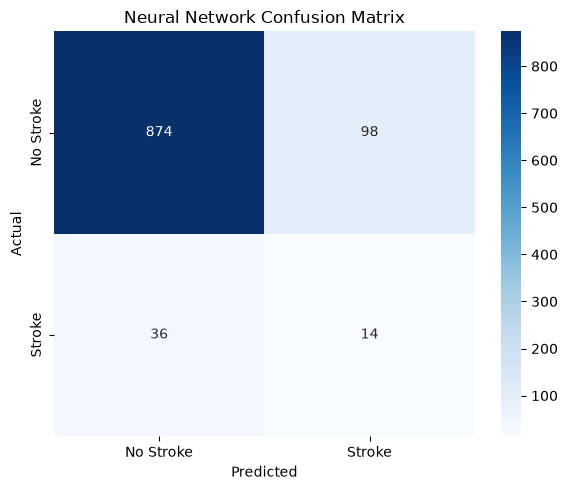

In [8]:
cm_dl = confusion_matrix(y_test, y_pred_dl)
tn, fp, fn, tp = cm_dl.ravel()

print('True Negative: ', tn)
print('False Positive:', fp)
print('False Negative:', fn)
print('True Positive: ', tp)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_dl, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Stroke', 'Stroke'],
            yticklabels=['No Stroke', 'Stroke'])
plt.title('Neural Network Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

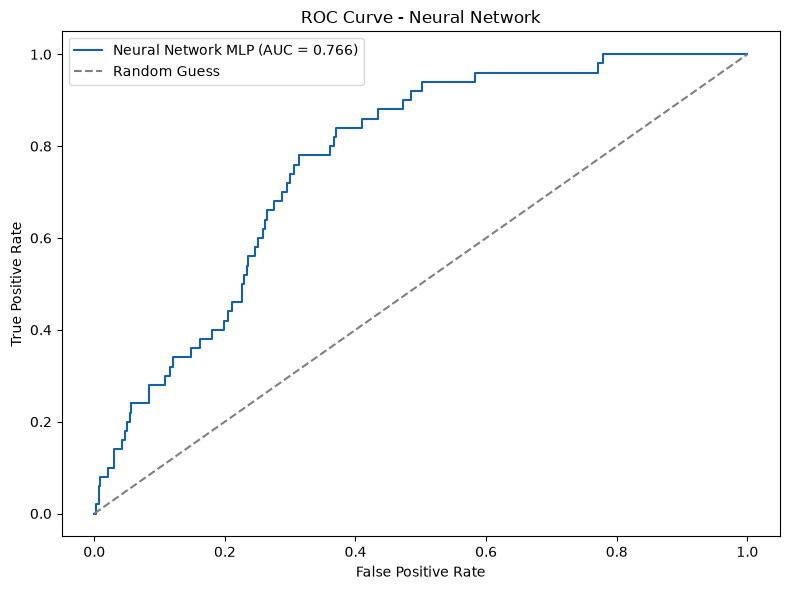

In [9]:
fpr_dl, tpr_dl, _ = roc_curve(y_test, y_pred_proba_dl)
auc_dl = roc_auc_score(y_test, y_pred_proba_dl)

plt.figure(figsize=(8, 6))
plt.plot(fpr_dl, tpr_dl, color='#185FA5',
         label=f'Neural Network MLP (AUC = {round(auc_dl, 3)})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Neural Network')
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# comparing ML vs DL results
import joblib

# loading saved ML model
ml_model = joblib.load(r'C:\Users\Ar\Desktop\multi-model-strok-prediction\models\best_ml_model.pkl')
ml_scaler = joblib.load(r'C:\Users\Ar\Desktop\multi-model-strok-prediction\models\scaler.pkl')

# scaling test data with ML scaler
X_test_ml_scaled = ml_scaler.transform(X_test)

# ML predictions
ml_pred = ml_model.predict(X_test_ml_scaled)
ml_pred_proba = ml_model.predict_proba(X_test_ml_scaled)[:, 1]

# comparison table
comparison = {
    'Model': ['XGBoost (ML)', 'Neural Network (DL)'],
    'Accuracy': [
        round(accuracy_score(y_test, ml_pred) * 100, 2),
        round(accuracy_score(y_test, y_pred_dl) * 100, 2)
    ],
    'Precision': [
        round(precision_score(y_test, ml_pred) * 100, 2),
        round(precision_score(y_test, y_pred_dl) * 100, 2)
    ],
    'Recall': [
        round(recall_score(y_test, ml_pred) * 100, 2),
        round(recall_score(y_test, y_pred_dl) * 100, 2)
    ],
    'F1 Score': [
        round(f1_score(y_test, ml_pred) * 100, 2),
        round(f1_score(y_test, y_pred_dl) * 100, 2)
    ],
    'AUC': [
        round(roc_auc_score(y_test, ml_pred_proba), 3),
        round(roc_auc_score(y_test, y_pred_proba_dl), 3)
    ]
}

comparison_df = pd.DataFrame(comparison)
print('ML vs DL Comparison:')
print(comparison_df)

ML vs DL Comparison:
                 Model  Accuracy  Precision  Recall  F1 Score    AUC
0         XGBoost (ML)     93.64      25.81    16.0     19.75  0.786
1  Neural Network (DL)     86.89      12.50    28.0     17.28  0.766


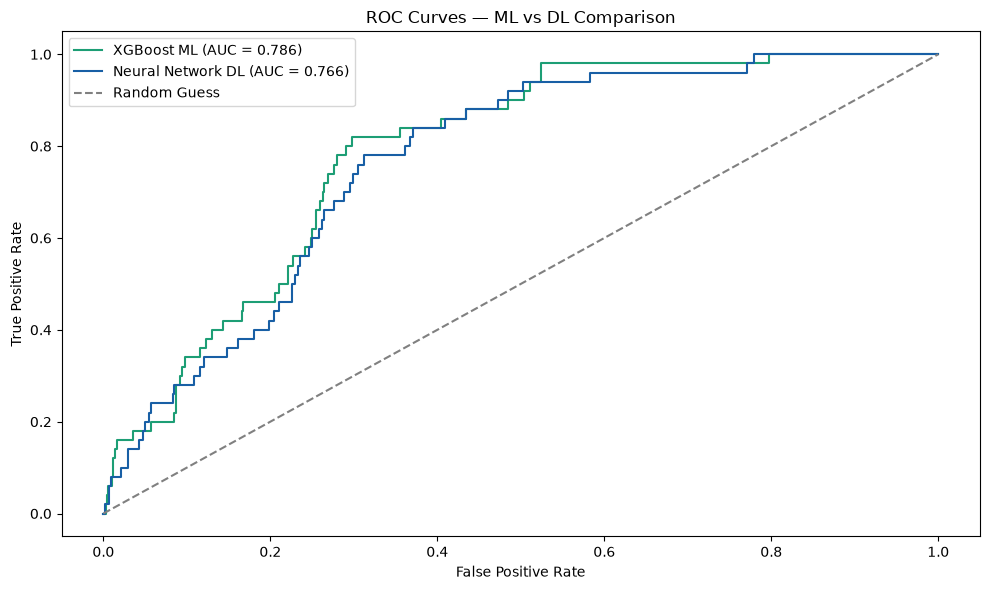

In [14]:
# comparing ROC curves of both models visually
fpr_ml, tpr_ml, _ = roc_curve(y_test, ml_pred_proba)
auc_ml = roc_auc_score(y_test, ml_pred_proba)

fpr_dl, tpr_dl, _ = roc_curve(y_test, y_pred_proba_dl)
auc_dl = roc_auc_score(y_test, y_pred_proba_dl)

plt.figure(figsize=(10, 6))
plt.plot(fpr_ml, tpr_ml, color='#1D9E75',
         label=f'XGBoost ML (AUC = {round(auc_ml, 3)})')
plt.plot(fpr_dl, tpr_dl, color='#185FA5',
         label=f'Neural Network DL (AUC = {round(auc_dl, 3)})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — ML vs DL Comparison')
plt.legend()
plt.tight_layout()
plt.show()

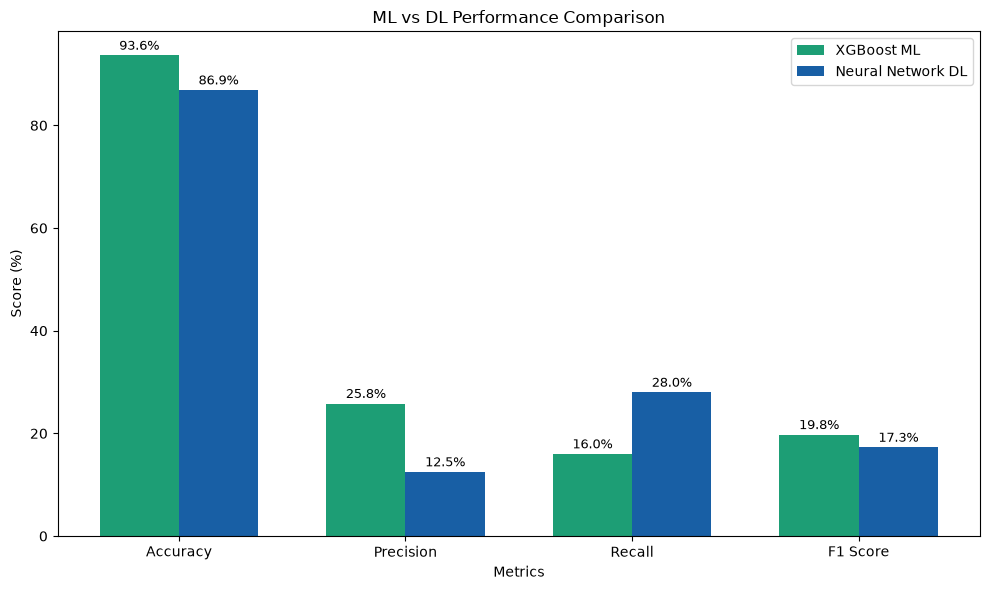

In [15]:
# visual bar chart comparing all metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
ml_scores = [
    round(accuracy_score(y_test, ml_pred) * 100, 2),
    round(precision_score(y_test, ml_pred) * 100, 2),
    round(recall_score(y_test, ml_pred) * 100, 2),
    round(f1_score(y_test, ml_pred) * 100, 2)
]
dl_scores = [
    round(accuracy_score(y_test, y_pred_dl) * 100, 2),
    round(precision_score(y_test, y_pred_dl) * 100, 2),
    round(recall_score(y_test, y_pred_dl) * 100, 2),
    round(f1_score(y_test, y_pred_dl) * 100, 2)
]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, ml_scores, width, label='XGBoost ML', color='#1D9E75')
bars2 = ax.bar(x + width/2, dl_scores, width, label='Neural Network DL', color='#185FA5')

ax.set_xlabel('Metrics')
ax.set_ylabel('Score (%)')
ax.set_title('ML vs DL Performance Comparison')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()

# adding value labels on bars
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [16]:
# saving neural network model
joblib.dump(model_dl,
            r'C:\Users\Ar\Desktop\multi-model-strok-prediction\models\dl_model.pkl')
print('Deep Learning model saved!')

Deep Learning model saved!
